# T15: every guess_* returns [] instead of raising

Companion notebook to `README.md`. Regenerates every figure in `figures/` from `benchmarks/baselines/synth200_s0.json` (before), `runs/t15_after/` (after) and the wavelet tables in `data/` (written by `make_data.py`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-14_t15-no-raise-all-guess-methods"
FIG, DATA = REPORT / "figures", REPORT / "data"
FIG.mkdir(exist_ok=True)
import evaluation as ev

before = json.loads((REPO / "benchmarks/baselines/synth200_s0.json").read_text())
after = json.loads((REPO / "runs/t15_after/metrics.json").read_text())
per_method = pd.read_csv(REPO / "runs/t15_after/per_method.csv")
w_before = pd.read_csv(DATA / "wavelet_head.csv")
w_after = pd.read_csv(DATA / "wavelet_t15.csv")
spectra = json.loads((DATA / "wavelet_head.spectra.json").read_text())

## Error rate per method, before vs after

Before = committed baseline (main at 1a076f0 plus T4); after = this branch. Only `wavelet` raised on this suite.

                    before  after
acf_fft              0.000    0.0
acf_fft_highpass     0.000    0.0
acf_fft_short        0.000    0.0
lombscargle          0.000    0.0
lombscargle_short    0.000    0.0
pairwise_histogram   0.000    0.0
wavelet              0.035    0.0


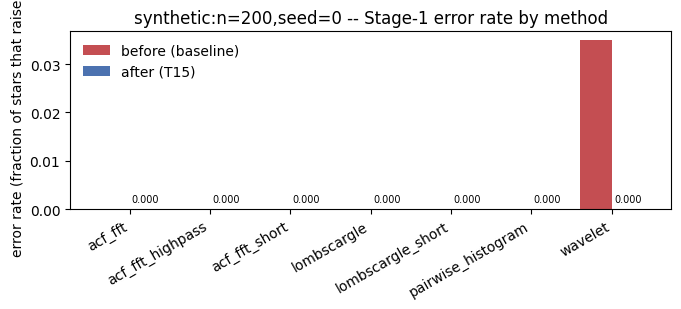

In [2]:
methods = sorted(after["methods"])
tab = pd.DataFrame({
    "before": [before["methods"][m]["overall"]["error_rate"] for m in methods],
    "after": [after["methods"][m]["overall"]["error_rate"] for m in methods],
}, index=methods)
print(tab)
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(methods))
ax.bar(x - 0.2, tab["before"], 0.4, label="before (baseline)", color="#c44e52")
ax.bar(x + 0.2, tab["after"], 0.4, label="after (T15)", color="#4c72b0")
for xi, v in zip(x, tab["after"]):
    ax.text(xi + 0.2, v + 0.001, f"{v:.3f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x, methods, rotation=30, ha="right")
ax.set_ylabel("error rate (fraction of stars that raised)")
ax.set_title("synthetic:n=200,seed=0 -- Stage-1 error rate by method")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "error_rate_by_method.png", dpi=130)

## Wavelet: error rate and recall by period bin

               error_rate    recall
before 1-3d      0.066667  0.577778
before 10-30d    0.000000  0.883721
before 3-10d     0.027778  0.944444
before <1d       0.044118  0.426471
before >30d      0.000000  1.000000
after 1-3d       0.000000  0.577778
after 10-30d     0.000000  0.883721
after 3-10d      0.000000  0.944444
after <1d        0.000000  0.426471
after >30d       0.000000  1.000000


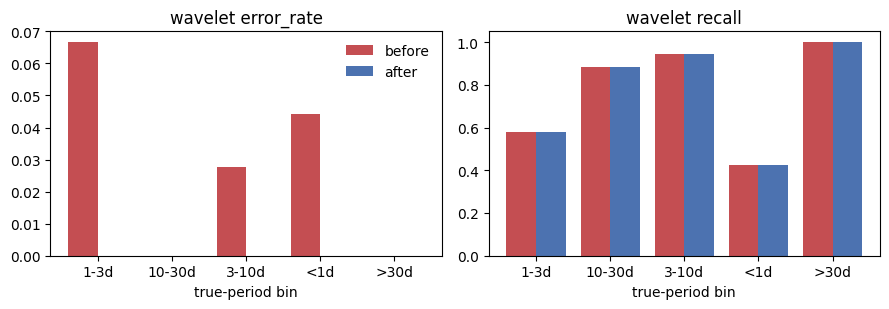

In [3]:
bins = list(before["methods"]["wavelet"]["by_bin"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, key in zip(axes, ["error_rate", "recall"]):
    b = [before["methods"]["wavelet"]["by_bin"][k][key] for k in bins]
    a = [after["methods"]["wavelet"]["by_bin"][k][key] for k in bins]
    x = np.arange(len(bins))
    ax.bar(x - 0.2, b, 0.4, label="before", color="#c44e52")
    ax.bar(x + 0.2, a, 0.4, label="after", color="#4c72b0")
    ax.set_xticks(x, bins); ax.set_title(f"wavelet {key}"); ax.set_xlabel("true-period bin")
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "wavelet_error_recall_by_bin.png", dpi=130)
print(pd.DataFrame({k: [before["methods"]["wavelet"]["by_bin"][b][k] for b in bins] +
                    [after["methods"]["wavelet"]["by_bin"][b][k] for b in bins]
                    for k in ["error_rate", "recall"]},
                   index=[f"before {b}" for b in bins] + [f"after {b}" for b in bins]))

## Which stars raised in wavelet, and why

`make_data.py` reran `guess_wavelet` exactly as the scorecard calls it, once with the HEAD code and once with this branch.

In [4]:
m = w_before.merge(w_after, on="star_id", suffixes=("_head", "_t15"))
raised = m[m.error_head.notna()]
print(raised[["star_id", "true_period_head", "snr_head", "inclination_head", "error_head", "n_candidates_t15", "error_t15"]].to_string(index=False))
print("\nstars whose candidate count changed outside the raised set:",
      int(((m.n_candidates_head != m.n_candidates_t15) & m.error_head.isna()).sum()))

       star_id  true_period_head  snr_head  inclination_head                                                                                                                               error_head  n_candidates_t15  error_t15
synth-s0-00010          3.026239 16.173070         14.965898 RuntimeError: guess_wavelet: no wavelet GWPS peak exceeded min_peak_snr; try lowering min_peak_snr or widening [min_period, max_period].                 0        NaN
synth-s0-00048          1.014641  1.999966         68.215756 RuntimeError: guess_wavelet: no wavelet GWPS peak exceeded min_peak_snr; try lowering min_peak_snr or widening [min_period, max_period].                 0        NaN
synth-s0-00055          0.532495  2.064063         46.500003 RuntimeError: guess_wavelet: no wavelet GWPS peak exceeded min_peak_snr; try lowering min_peak_snr or widening [min_period, max_period].                 0        NaN
synth-s0-00057          0.298402  1.028530         39.275066 RuntimeError: guess_wavelet: no

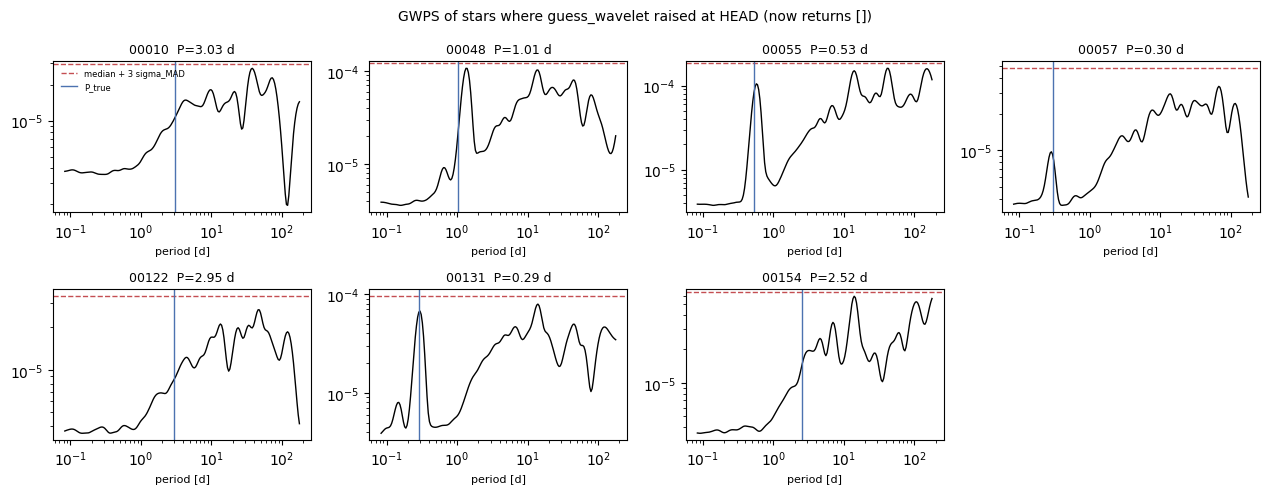

In [5]:
ids = list(spectra)
ncol = 4
nrow = int(np.ceil(len(ids) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.5 * nrow), squeeze=False)
for ax, sid in zip(axes.flat, ids):
    s = spectra[sid]
    ax.loglog(s["periods"], s["gwps"], color="k", lw=1)
    ax.axhline(s["threshold"], color="#c44e52", ls="--", lw=1, label="median + 3 sigma_MAD")
    ax.axvline(s["true_period"], color="#4c72b0", lw=1, label="P_true")
    ax.set_title(f"{sid[-5:]}  P={s['true_period']:.2f} d", fontsize=9)
    ax.set_xlabel("period [d]", fontsize=8)
for ax in list(axes.flat)[len(ids):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=6, frameon=False)
fig.suptitle("GWPS of stars where guess_wavelet raised at HEAD (now returns [])", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "wavelet_raised_gwps.png", dpi=130)

## Final answer: before vs after

`wavelet` is not in the pipeline's pooled methods (`pairwise_histogram, lombscargle, acf_fft`), so final outcomes should be unchanged.

In [6]:
keys = ["correct", "diffrot", "half", "double", "wrong", "none", "success"]
print(pd.DataFrame({"before": [before["final"]["overall"][k] for k in keys],
                    "after": [after["final"]["overall"][k] for k in keys]}, index=keys))
fb = pd.read_csv(DATA / "final_before_after.csv")
print("\nper-star final outcome, before (rows) vs after (cols):")
print(pd.crosstab(fb.final_outcome_before, fb.final_outcome_after))
rel = (fb.final_period_after - fb.final_period_before).abs() / fb.final_period_before
print("stars with any final-period difference: %d, max relative diff %.2e" % ((rel > 0).sum(), rel.max()))
print("n_pooled differences:", int((fb.n_pooled_before != fb.n_pooled_after).sum()))
print("\nStage-1 per-method diff vs the pre-T4 v2 run:")
print(pd.read_csv(DATA / "stage1_diff_by_method.csv").to_string(index=False))
print("\nmedian s/star (wall, per worker) before %.2f, after %.2f" % (before["runtime"]["median_seconds"],
                                                  after["runtime"]["median_seconds"]))

         before  after
correct   0.460  0.460
diffrot   0.210  0.210
half      0.035  0.035
double    0.000  0.000
wrong     0.055  0.055
none      0.240  0.240
success   0.670  0.670

per-star final outcome, before (rows) vs after (cols):
final_outcome_after   correct  diffrot  half  none  wrong
final_outcome_before                                     
correct                    92        0     0     0      0
diffrot                     0       42     0     0      0
half                        0        0     7     0      0
none                        0        0     0    48      0
wrong                       0        0     0     0     11
stars with any final-period difference: 18, max relative diff 4.66e-05
n_pooled differences: 0

Stage-1 per-method diff vs the pre-T4 v2 run:
            method   n  errors_before  errors_after  outcome_changed  n_candidates_changed  top1_max_rel_diff
           acf_fft 200              0             0                0                     0       0.000